<a href="https://colab.research.google.com/github/ShaneGray83/skills-introduction-to-github/blob/main/DSIF_Assignment_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# High level outline to the approach

#Step 1: Setup - Loading of data & Libraries
#Step 2: Preparing Data: Addressing missing values, encoding categorical variables, and normalising numerical features
#Step 3: Features: Selecting features relevant to risk
#Step 4: Train a baseline model: Using Logistic Regression Model (Model 1), Opting Gradient Boosting as we reduce both bias & variance, and it is a small sample (100k) as Model 2
#Step 5: Evaluate: Assess the effectiveness of the model with effective metrics - Check for over fitting risk specifically as it is a risk in Gradient Boosting
#Step 6: Optomizing/ Hyperparameter tuning: Adjust decision thresholds based on expected profit/ loss


# Step 1
# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import classification_report, roc_auc_score
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression

# Check if in Google Colab environment
try:
    from google.colab import drive

    # Mount drive
    drive.mount('/content/drive')

    # Set up path to Python material parent folder
    path_python_material = rf"drive/MyDrive/Assignments/Data Cleaning"
        # If unsure, print current directory path by executing the following in a new cell:
        # !pwd
    IN_COLAB = True
except:
    IN_COLAB = False
    print("Not running on CoLab")


Mounted at /content/drive


In [ ]:
# Import Data
df = pd.read_csv(f"{path_python_material}/df_out_dsif5.csv")

df.head(5)

,id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,emp_title,...,int_rate_clean,term_numeric,debt_to_income,loan_amnt_log,grade_encoded,loan_amnt_std,annual_inc_std,loan_amnt_norm,annual_inc_norm,loan_default
0,167338079,4000.0,4000.0,4000.0,36 months,13.08%,134.93,B,B5,cashier,...,0.1308,36.0,0.083333,8.294300,1,-1.196895,-0.367206,0.083969,0.004364,False
1,71016917,24000.0,24000.0,24000.0,60 months,9.16%,500.07,B,B2,ABM,...,0.0916,60.0,0.421053,10.085851,1,0.915452,-0.264024,0.592875,0.005182,False
2,39589826,5000.0,5000.0,5000.0,36 months,10.49%,162.49,B,B3,driver,...,0.1049,36.0,0.090909,8.517393,1,-1.091278,-0.286953,0.109415,0.005000,False
3,134798709,24000.0,24000.0,24000.0,60 months,11.05%,522.42,B,B4,NaN,...,0.1105,60.0,0.551724,10.085851,1,0.915452,-0.418798,0.592875,0.003955,False
4,127097355,14000.0,14000.0,14000.0,60 months,13.59%,322.79,C,C2,Shipping Clerk,...,0.1359,60.0,0.291667,9.546884,2,-0.140722,-0.367206,0.338422,0.004364,False


In [ ]:
from scipy.stats import skew

mean_loan = df['loan_amnt'].mean()
median_loan = df['loan_amnt'].median()
mode_loan = df['loan_amnt'].mode()[0]
std_loan = df['loan_amnt'].std()
percentile_loan = np.percentile(df['loan_amnt'], [25, 50, 75])
skewness_loan = skew(df['loan_amnt'])

print(f"Mean Loan Amount: {mean_loan}")
print(f"Median Loan Amount: {median_loan}")
print(f"Mode Loan Amount: {mode_loan}")
print(f"Standard Deviation of Loan Amount: {std_loan}")
print(f"Loan Amount Percentiles: {percentile_loan}")
print(f"Skewness of Loan Amount: {skewness_loan}")

Mean Loan Amount: 15332.373
Median Loan Amount: 13000.0
Mode Loan Amount: 10000.0
Standard Deviation of Loan Amount: 9468.189883376823
Loan Amount Percentiles: [ 8000. 13000. 20000.]
Skewness of Loan Amount: 0.7887250378394999


In [ ]:
from pickle import LIST
LIST = df.columns.tolist()
print(LIST)

['id', 'loan_amnt', 'funded_amnt', 'funded_amnt_inv', 'term', 'int_rate', 'installment', 'grade', 'sub_grade', 'emp_title', 'emp_length', 'home_ownership', 'annual_inc', 'verification_status', 'issue_d', 'loan_status', 'pymnt_plan', 'url', 'purpose', 'title', 'zip_code', 'addr_state', 'dti', 'delinq_2yrs', 'earliest_cr_line', 'fico_range_low', 'fico_range_high', 'inq_last_6mths', 'mths_since_last_delinq', 'mths_since_last_record', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'initial_list_status', 'out_prncp', 'out_prncp_inv', 'total_pymnt', 'total_pymnt_inv', 'total_rec_prncp', 'total_rec_int', 'total_rec_late_fee', 'recoveries', 'collection_recovery_fee', 'last_pymnt_d', 'last_pymnt_amnt', 'next_pymnt_d', 'last_credit_pull_d', 'last_fico_range_high', 'last_fico_range_low', 'collections_12_mths_ex_med', 'mths_since_last_major_derog', 'policy_code', 'application_type', 'annual_inc_joint', 'dti_joint', 'verification_status_joint', 'acc_now_delinq', 'tot_coll_amt', 'tot

In [ ]:
# Step 3
features = ['fico_range_high','fico_range_low', 'annual_inc', 'dti']
x = df[features]
y = df['loan_default']


In [ ]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy='mean')
x = imputer.fit_transform(x)

In [ ]:
# Step 4

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score

imputer = SimpleImputer(strategy='mean')

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=20)

for dframe in [X_train, X_test, y_train, y_test]:
    print(f"Shape: {dframe.shape}")

Shape: (80000, 4)
Shape: (20000, 4)
Shape: (80000,)
Shape: (20000,)


In [ ]:
model = LogisticRegression()

In [ ]:
model.fit(X_train, y_train)

LogisticRegression()

In [ ]:
predictions = model.predict(X_test)
predictions


array([False, False, False, ..., False, False, False])

In [ ]:
# Evaluating the classification model

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

accuracy = accuracy_score(y_test, predictions)
precision = precision_score(y_test, predictions)
recall = recall_score(y_test, predictions)
f1 = f1_score(y_test, predictions)
roc_auc = roc_auc_score(y_test, predictions)

# Show Confusion Matrix
cm = confusion_matrix(y_test, predictions)

print(f"Accuracy: {accuracy}")
print(f"Precision: {precision}")
print(f"Recall: {recall}")
print(f"F1 Score: {f1}")
print(f"ROC AUC Score: {roc_auc}")
print(cm)


Accuracy: 0.8776
Precision: 0.0
Recall: 0.0
F1 Score: 0.0
ROC AUC Score: 0.5
[[17552     0]
 [ 2448     0]]


/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


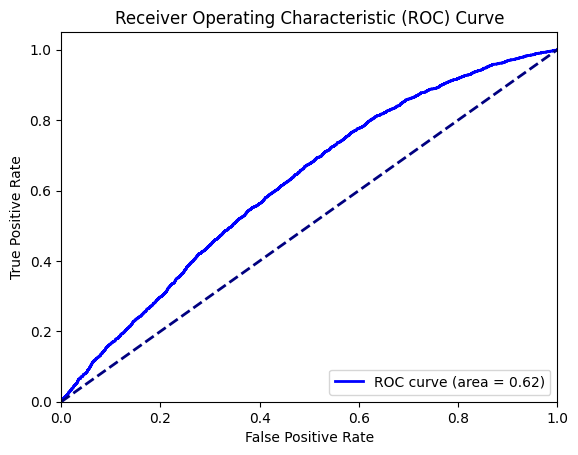

ROC AUC Score: 0.62


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve, auc, roc_auc_score

y_pred_prob = model.predict_proba(X_test)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, y_pred_prob)
roc_auc = auc(fpr, tpr)

# Visual Plot
plt.figure()
plt.plot(fpr, tpr, color='blue', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.show()

print (f'ROC AUC Score: {roc_auc_score(y_test, y_pred_prob):.2f}')


/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Gradient Boosting Accuracy: 0.8776
Gradient Boosting Precision: 0.0
Gradient Boosting Recall: 0.0
Gradient Boosting F1 Score: 0.0
Gradient Boosting ROC AUC Score: 0.5
[[17552     0]
 [ 2448     0]]


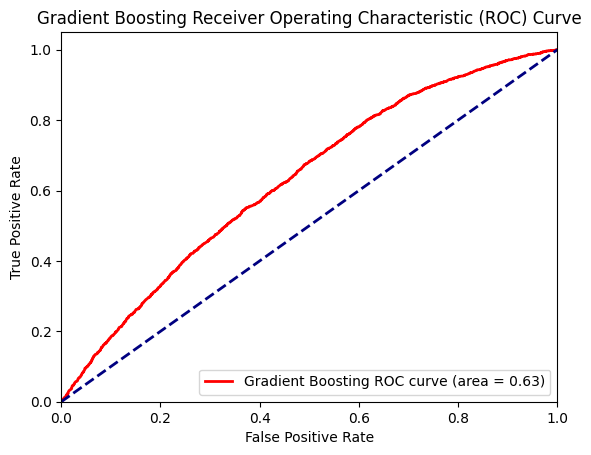

Gradient Boosting ROC AUC Score: 0.63


In [ ]:
# Model 2 - Gradient Boosting

import matplotlib.pyplot as plt

gb_model = GradientBoostingClassifier(random_state=20)
gb_model.fit(X_train, y_train)
gb_predictions = gb_model.predict(X_test)

# Evaluating the Gradient Boosting Model
gb_accuracy = accuracy_score(y_test, gb_predictions)
gb_precision = precision_score(y_test, gb_predictions)
gb_recall = recall_score(y_test, gb_predictions)
gb_f1 = f1_score(y_test, gb_predictions)
gb_roc_auc = roc_auc_score(y_test, gb_predictions)

# Show Confusion Matrix
gb_cm = confusion_matrix(y_test, gb_predictions)

print(f"Gradient Boosting Accuracy: {gb_accuracy}")
print(f"Gradient Boosting Precision: {gb_precision}")
print(f"Gradient Boosting Recall: {gb_recall}")
print(f"Gradient Boosting F1 Score: {gb_f1}")
print(f"Gradient Boosting ROC AUC Score: {gb_roc_auc}")
print(gb_cm)

# ROC Curve for Gradient Boosting
gb_y_pred_prob = gb_model.predict_proba(X_test)[:, 1]
gb_fpr, gb_tpr, gb_thresholds = roc_curve(y_test, gb_y_pred_prob)
gb_roc_auc = auc(gb_fpr, gb_tpr)

# Visual Plot
plt.figure()
plt.plot(gb_fpr, gb_tpr, color='red', lw=2, label=f'Gradient Boosting ROC curve (area = {gb_roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Gradient Boosting Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.show()

print(f'Gradient Boosting ROC AUC Score: {roc_auc_score(y_test, gb_y_pred_prob):.2f}')



In [ ]:
# Step 5: Overfitting

from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score

kfold = KFold(n_splits=5, shuffle=True, random_state=20)

def cv_score(model, X, y, cv=5):
  scores = cross_val_score(model, X, y, cv=cv, scoring='accuracy')
  cv_scores = cross_val_score(model, X, y, cv=5, scoring='accuracy')

# Perform cross-validation

  print('CV accuracy scores: %s' % scores)
  print('CV accuracy: %.3f +/- %.3f' % (np.mean(scores), np.std(scores)))

In [ ]:
# Step 6: hyperparameter tuning of gradient boosting model

from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import roc_auc_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score
import pandas as pd

# Define the parameter grid for hyperparameter tuning
param_grid = {'n_estimators': [50, 100, 200],  # Number of boosting stages
    'learning_rate': [0.01, 0.1, 0.5],  # Step size shrinkage used in update to prevent overfitting
    'max_depth': [3, 5, 7],  # Maximum depth of the individual regression estimators
    'min_samples_split': [2, 5, 10], # Minimum number of samples required to split an internal node
    'min_samples_leaf': [1, 2, 4] # Minimum number of samples required to be at a leaf node.
              }

# Create a Gradient Boosting Classifier
gb_model = GradientBoostingClassifier(random_state=20)

# Create GridSearchCV object
grid_search = GridSearchCV(estimator=gb_model, param_grid=param_grid, cv=5, scoring='roc_auc', n_jobs=-1)

# Define features
def get_features(df):
    features = ['fico_range_high','fico_range_low', 'annual_inc', 'dti']
    x = df[features]
    y = df['loan_default']
    return x, y

    x, y = get_features(df)

# Split data into training and testing sets
    X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=20)

# Fit the GridSearchCV object to the training data
    grid_search.fit(X_train, y_train)

# Get the best hyperparameters
    best_params = grid_search.best_params_
    print(f"Best Hyperparameters: {best_params}")

# Get the best model
    best_gb_model = grid_search.best_estimator_

# Evaluate the best model
    best_gb_predictions = best_gb_model.predict(X_test)
    best_gb_roc_auc = roc_auc_score(y_test, best_gb_predictions)

    print(f"Best Gradient Boosting ROC AUC Score: {best_gb_roc_auc}")

In [ ]:
# Part 2: Misclassification cost of false positives and false negatives

# Assuming 'cm' is the confusion matrix from the Logistic Regression model
# and 'gb_cm' is the confusion matrix from the Gradient Boosting model.

# Extract values from the confusion matrices
TN_lr, FP_lr, FN_lr, TP_lr = cm.ravel()
TN_gb, FP_gb, FN_gb, TP_gb = gb_cm.ravel()

# Define costs (replace with actual costs)
cost_fp = 100  # Cost of a false positive
cost_fn = 1000  # Cost of a false negative

# Calculate misclassification costs
misclassification_cost_lr = (FP_lr * cost_fp) + (FN_lr * cost_fn)
misclassification_cost_gb = (FP_gb * cost_fp) + (FN_gb * cost_fn)

print(f"Logistic Regression Misclassification Cost: {misclassification_cost_lr}")
print(f"Gradient Boosting Misclassification Cost: {misclassification_cost_gb}")

Logistic Regression Misclassification Cost: 2448000
Gradient Boosting Misclassification Cost: 2448000


In [ ]:
# Part 3: PoC to predict loan_amnt based on variables emp_length, home_ownership and annual_inc

import pandas as pd
from sklearn.linear_model import LinearRegression

features = ['emp_length', 'home_ownership', 'annual_inc']
X = df[features]
y = df['loan_amnt']

# Convert 'emp_length' to numerical if it is categorical
if pd.api.types.is_string_dtype(X['emp_length']):
    X['emp_length'] = X['emp_length'].str.replace(r'\D+', '', regex=True).astype(float)

# Handle missing values in 'emp_length'
    imputer_emp = SimpleImputer(strategy='mean')
    X['emp_length'] = imputer_emp.fit_transform(X[['emp_length']])

# One-hot encode 'home_ownership'
    X = pd.get_dummies(X, columns=['home_ownership'], drop_first=True)

# Handle missing values in 'annual_inc'
    imputer_annual_inc = SimpleImputer(strategy='mean')
    X['annual_inc'] = imputer_annual_inc.fit_transform(X[['annual_inc']])

# Split data into training and testing sets
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialize and train a linear regression model
    model = LinearRegression()
    model.fit(X_train, y_train)

# Make predictions
    y_pred = model.predict(X_test)

# Evaluate the model (example: using R-squared)
    from sklearn.metrics import r2_score
    r2 = r2_score(y_test, y_pred)

    print(f"R-squared: {r2}")